In [30]:
import EFC_learningfMRI.globals as gl
import os
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from imaging_pipelines.vis import plot_surf
from matplotlib.colors import LinearSegmentedColormap, Normalize
import nibabel as nb
from matplotlib.cm import ScalarMappable
import numpy as np
import pingouin as pg
import  EFC_learningfMRI.vis as vis
import EFC_learningfMRI.util as util

# Univariate activation
## Load data

In [31]:
H = 'L'
atlas = 'ROI'
rois = gl.rois[atlas]
#rois = ['PMd', 'M1', 'S1', 'SPLa']
glm = 3
stat = 'nanmean'
activation = pd.read_csv(os.path.join(gl.baseDir, f'{gl.glmDir}{glm}', 'ROI.activation.tsv'), sep='\t')
N = activation.sn.nunique()
activation = activation.groupby(['chord', 'session', 'sn', 'regionname', 'Hem']).mean(numeric_only=True).reset_index()
activation = activation[activation.Hem==H]
hue_order = ['trained', 'untrained']
palette = ['red', 'blue']

print(f'N={activation.sn.nunique()}')

N=16


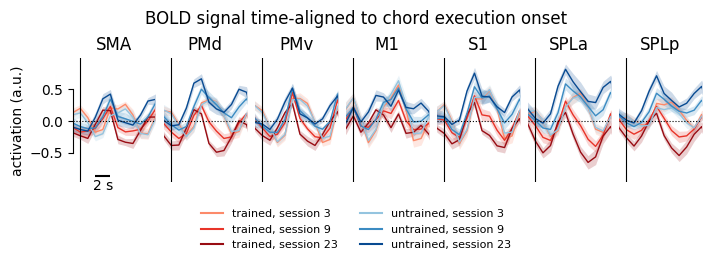

In [32]:
bold = pd.read_csv(os.path.join(gl.baseDir, f'{gl.glmDir}{glm}', 'bold_segmented.tsv'), sep='\t')
bold = bold[bold.Hem==H]

subj_mean  = bold.groupby(['sn', 'roi', 'session']).signal.transform('mean')
bold['signal_dm'] = bold.signal - subj_mean

# average over trials within participant, so the shaded band is the SEM across participants
bold_g = bold.groupby(['chord', 'time', 'session', 'roi', 'sn']).mean(numeric_only=True).reset_index()
bold_g['cond'] = bold_g.chord + ', session ' + bold_g.session.astype(str)

# one shade per session: light -> dark red for trained, light -> dark blue for untrained
shades = np.linspace(.4, .9, len(gl.sessions))
cond_palette = {}
for chord, cmap_name in zip(hue_order, ['Reds', 'Blues']):
    for sess, c in zip(gl.sessions, plt.get_cmap(cmap_name)(shades)):
        cond_palette[f'{chord}, session {sess}'] = c

fig, axs = plt.subplots(1, len(rois), sharex=True, sharey=True, figsize=(7, 2.5), constrained_layout=True)
for ax, roi in zip(axs, rois):
    sb.lineplot(ax=ax, data=bold_g[bold_g.roi==roi], x='time', y='signal_dm', hue='cond',
                hue_order=list(cond_palette), palette=cond_palette, errorbar='se', lw=1, err_kws={'lw': 0})
    ax.set_title(roi)
    ax.axhline(0, color='k', lw=.8, ls=':')
    ax.axvline(0, color='k', lw=.8, ls='-')
    ax.set_xlim([-1, 10])
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    ax.legend([], frameon=False)

# despine after all panels are drawn, so the trim uses the final shared limits:
# trimmed y spine on the first panel only (x axis replaced by a scale bar), no spines or ticks on the others
sb.despine(ax=axs[0], bottom=True, trim=True)
axs[0].tick_params(bottom=False, labelbottom=False)
for ax in axs[1:]:
    sb.despine(ax=ax, left=True, bottom=True)
    ax.tick_params(left=False, bottom=False, labelbottom=False)

# 1 s scale bar from chord onset, along the bottom of the first panel
y_bar = axs[0].get_ylim()[0]
axs[0].plot([2, 4], [y_bar, y_bar], color='k', lw=1.5, clip_on=False, solid_capstyle='butt')
axs[0].annotate('2 s', xy=(3, y_bar), xytext=(0, -2), textcoords='offset points', ha='center', va='top', fontsize=10)

handles = [Line2D([0], [0], color=c, lw=1.5) for c in cond_palette.values()]
fig.legend(handles, list(cond_palette), frameon=False, loc='outside lower center', fontsize=8, ncol=2)
axs[0].set_ylabel('activation (a.u.)')

fig.suptitle('BOLD signal time-aligned to chord execution onset')

fig.savefig(os.path.join(gl.figDir, f'BOLD.glm{glm}.{atlas}.{H}.pdf'))

plt.show()

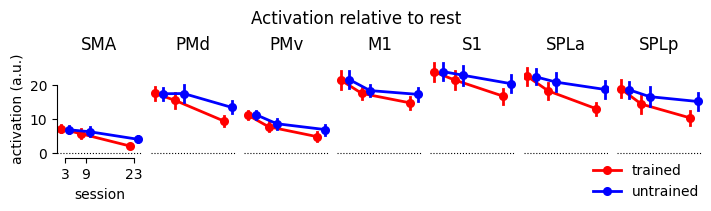

In [33]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(7, 2), constrained_layout=True)
vis.plot_im_sess(fig, axs, activation, rois=rois, roi_col='regionname', y=stat, hue='chord', hue_order=hue_order, palette=palette, add_zero=True, dodge=.4)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('activation (a.u.)')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='lower right')
axs[0].set_xlabel('session')
fig.suptitle(f'Activation relative to rest')

fig.savefig(os.path.join(gl.figDir, f'activation.glm{glm}.{atlas}.{H}.pdf'))

plt.show()

In [34]:
# two-way repeated-measures ANOVA (session x chord) on activation, one per ROI.
# p_GG_corr is Greenhouse-Geisser corrected (it only differs from p_unc for the terms involving session, which has 3 levels)
anova = pd.concat([pg.rm_anova(data=activation[activation.regionname==roi], dv=stat, within=['session', 'chord'],
                               subject='sn', detailed=True, effsize='np2').assign(regionname=roi)
                   for roi in rois], ignore_index=True)

print(anova[['regionname', 'Source', 'F', 'ddof1', 'ddof2', 'p_unc', 'p_GG_corr', 'np2', 'eps']].round(4).to_string(index=False))

regionname          Source       F  ddof1  ddof2  p_unc  p_GG_corr    np2    eps
       SMA         session  8.5077      2     30 0.0012     0.0020 0.3619 0.8837
       SMA           chord 13.4543      1     15 0.0023     0.0023 0.4728 1.0000
       SMA session * chord  7.4122      2     30 0.0024     0.0114 0.3307 0.5858
       PMd         session  9.4759      2     30 0.0006     0.0016 0.3872 0.8166
       PMd           chord 26.0800      1     15 0.0001     0.0001 0.6349 1.0000
       PMd session * chord 15.5406      2     30 0.0000     0.0005 0.5088 0.6267
       PMv         session 13.8173      2     30 0.0001     0.0004 0.4795 0.7349
       PMv           chord 14.3000      1     15 0.0018     0.0018 0.4881 1.0000
       PMv session * chord  8.8887      2     30 0.0009     0.0051 0.3721 0.6315
        M1         session  4.6737      2     30 0.0171     0.0242 0.2376 0.8283
        M1           chord 19.8875      1     15 0.0005     0.0005 0.5700 1.0000
        M1 session * chord  

In [35]:
ttest = util.ttest_im_sess(activation, rois, y=stat, roi_col='regionname', hue='chord', hue_order=hue_order)
ttest['regionname'] = pd.Categorical(ttest.regionname, categories=rois, ordered=True)  # ROIs in gl.rois[atlas] order
ttest.sort_values(by=['session', 'regionname'], inplace=True)

print(ttest[['T', 'dof', 'p_val', 'cohen_d', 'CI95', 'regionname', 'session']])

plt.show()

           T  dof     p_val   cohen_d            CI95 regionname  session
0   1.075546   15  0.299127  0.070709     [-0.3, 0.9]        SMA        3
3   0.307448   15  0.762730  0.017572   [-0.78, 1.04]        PMd        3
6  -0.575639   15  0.573395  0.018366   [-0.43, 0.25]        PMv        3
9  -0.693428   15  0.498639  0.019584   [-0.82, 0.42]         M1        3
12 -0.419333   15  0.680916  0.013118   [-0.86, 0.57]         S1        3
15  0.230896   15  0.820516  0.010605    [-0.8, 0.99]       SPLa        3
18  0.646140   15  0.527951  0.030530   [-0.69, 1.29]       SPLp        3
1  -2.330118   15  0.034172  0.114943   [-1.2, -0.05]        SMA        9
4  -4.172881   15  0.000816  0.218492    [-3.1, -1.0]        PMd        9
7  -2.898383   15  0.011031  0.153129  [-1.53, -0.23]        PMv        9
10 -1.879608   15  0.079729  0.128500   [-1.77, 0.11]         M1        9
13 -2.136488   15  0.049526  0.127332   [-2.83, -0.0]         S1        9
16 -3.864178   15  0.001529  0.261584 

In [36]:
# summary table, ROIs as columns: rm-ANOVA (F, Greenhouse-Geisser corrected p) and
# paired t-tests trained vs. untrained in each session (negative t = lower activation for trained chords)
anova_rows = pd.DataFrame({
    'test'      : anova.Source.map({'session': 'ANOVA: session', 'chord': 'ANOVA: chord set', 'session * chord': 'ANOVA: session × chord set'}),
    'regionname': anova.regionname,
    'result'    : [f'F({d1:.0f},{d2:.0f}) = {F:.2f}, ' + ('p < .001' if p < .001 else 'p = ' + f'{p:.3f}'.lstrip('0'))
                   for d1, d2, F, p in zip(anova.ddof1, anova.ddof2, anova.F, anova.p_GG_corr)]})
ttest_rows = pd.DataFrame({
    'test'      : 't-test: session ' + ttest.session.astype(str),
    'regionname': ttest.regionname.astype(str),
    'result'    : [f't({dof:.0f}) = {T:.2f}, ' + ('p < .001' if p < .001 else 'p = ' + f'{p:.3f}'.lstrip('0'))
                   for dof, T, p in zip(ttest.dof, ttest['T'], ttest.p_val)]})

row_order   = list(anova_rows.test.unique()) + [f't-test: session {s}' for s in sorted(ttest.session.unique())]
stats_table = pd.concat([anova_rows, ttest_rows]).pivot(index='test', columns='regionname', values='result').loc[row_order, rois]
stats_table.columns.name = None
stats_table.index.name   = None

print(stats_table.to_markdown())
stats_table

|                            | SMA                       | PMd                       | PMv                       | M1                        | S1                        | SPLa                      | SPLp                      |
|:---------------------------|:--------------------------|:--------------------------|:--------------------------|:--------------------------|:--------------------------|:--------------------------|:--------------------------|
| ANOVA: session             | F(2,30) = 8.51, p = .002  | F(2,30) = 9.48, p = .002  | F(2,30) = 13.82, p < .001 | F(2,30) = 4.67, p = .024  | F(2,30) = 6.12, p = .014  | F(2,30) = 12.69, p < .001 | F(2,30) = 11.74, p = .001 |
| ANOVA: chord set           | F(1,15) = 13.45, p = .002 | F(1,15) = 26.08, p < .001 | F(1,15) = 14.30, p = .002 | F(1,15) = 19.89, p < .001 | F(1,15) = 12.91, p = .003 | F(1,15) = 22.11, p < .001 | F(1,15) = 16.66, p < .001 |
| ANOVA: session × chord set | F(2,30) = 7.41, p = .011  | F(2,30) = 15.54, p < .001 | F(2,3

,SMA,PMd,PMv,M1,S1,SPLa,SPLp
ANOVA: session,"F(2,30) = 8.51, p = .002","F(2,30) = 9.48, p = .002","F(2,30) = 13.82, p < .001","F(2,30) = 4.67, p = .024","F(2,30) = 6.12, p = .014","F(2,30) = 12.69, p < .001","F(2,30) = 11.74, p = .001"
ANOVA: chord set,"F(1,15) = 13.45, p = .002","F(1,15) = 26.08, p < .001","F(1,15) = 14.30, p = .002","F(1,15) = 19.89, p < .001","F(1,15) = 12.91, p = .003","F(1,15) = 22.11, p < .001","F(1,15) = 16.66, p < .001"
ANOVA: session × chord set,"F(2,30) = 7.41, p = .011","F(2,30) = 15.54, p < .001","F(2,30) = 8.89, p = .005","F(2,30) = 7.11, p = .005","F(2,30) = 12.90, p < .001","F(2,30) = 19.69, p < .001","F(2,30) = 19.57, p < .001"
t-test: session 3,"t(15) = 1.08, p = .299","t(15) = 0.31, p = .763","t(15) = -0.58, p = .573","t(15) = -0.69, p = .499","t(15) = -0.42, p = .681","t(15) = 0.23, p = .821","t(15) = 0.65, p = .528"
t-test: session 9,"t(15) = -2.33, p = .034","t(15) = -4.17, p < .001","t(15) = -2.90, p = .011","t(15) = -1.88, p = .080","t(15) = -2.14, p = .050","t(15) = -3.86, p = .002","t(15) = -3.53, p = .003"
t-test: session 23,"t(15) = -3.43, p = .004","t(15) = -5.30, p < .001","t(15) = -3.65, p = .002","t(15) = -4.39, p < .001","t(15) = -4.57, p < .001","t(15) = -5.10, p < .001","t(15) = -4.90, p < .001"


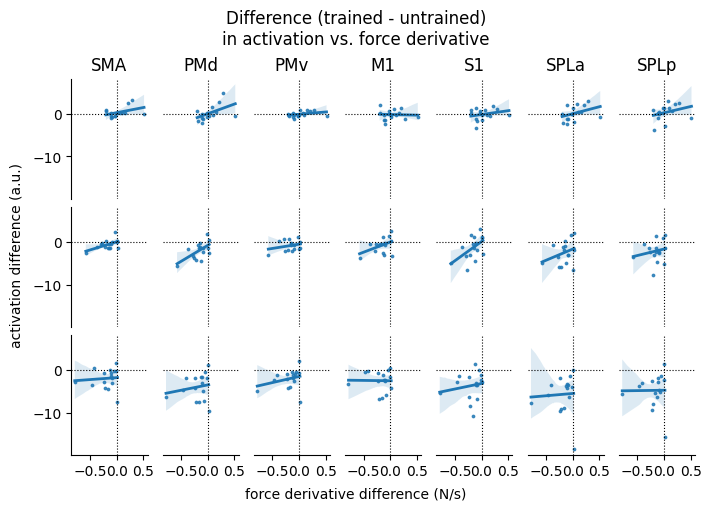

In [37]:
# regression analysis
# trained - untrained activation vs. trained - untrained force derivative (averaged across fingers), across participants
force = pd.read_csv(os.path.join(gl.baseDir, gl.behavDir, 'force.session.avg.tsv'), sep='\t').rename(columns={'subNum': 'sn'})
force = force[force.session.isin(gl.sessions)]

diff_act   = util.diff_trained_untrained(activation, stat, on=['session', 'sn', 'regionname', 'Hem'])
diff_force = util.diff_trained_untrained(force, 'force_der', on=['session', 'sn'])

fig, axs = plt.subplots(len(gl.sessions), len(rois), constrained_layout=True, sharex=True, sharey=True, figsize=(7, 5))

for r, roi in enumerate(rois):
    for s, sess in enumerate(gl.sessions):
        ax   = axs[s, r]
        d    = diff_act[(diff_act.regionname==roi) & (diff_act.session==sess)][['sn', 'Diff']]
        f    = diff_force[diff_force.session==sess][['sn', 'Diff']]
        data = d.merge(f, on='sn', suffixes=('_act', '_force'))

        sb.regplot(data, x='Diff_force', y='Diff_act', ax=ax, scatter_kws={'s': 3}, line_kws={'lw': 2})

        ax.set_title(roi if s==0 else None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.axhline(0, color='k', lw=.8, ls=':')
        ax.axvline(0, color='k', lw=.8, ls=':')

        # left spine only in the first column, bottom spine only in the last row
        first_col = r == 0
        last_row  = s == len(gl.sessions) - 1
        sb.despine(ax=ax, left=not first_col, bottom=not last_row)
        ax.tick_params(left=first_col, bottom=last_row)

fig.supylabel('activation difference (a.u.)', fontsize=10)
fig.supxlabel('force derivative difference (N/s)', fontsize=10)
fig.suptitle('Difference (trained - untrained)\nin activation vs. force derivative')

plt.show()

   regionname  session      coef    ci_low   ci_high      tval      pval
0         SMA        3  0.225935 -0.352032  0.803903  0.838426  0.415878
1         PMd        3 -0.011214 -0.846115  0.823687 -0.028807  0.977425
2         PMv        3 -0.123864 -0.462126  0.214398 -0.785373  0.445323
3          M1        3 -0.192497 -0.848401  0.463406 -0.629461  0.539184
4          S1        3 -0.197322 -0.929124  0.534479 -0.578319  0.572235
5        SPLa        3 -0.006305 -0.882587  0.869977 -0.015433  0.987905
6        SPLp        3  0.206155 -0.788006  1.200316  0.444755  0.663296
7         SMA        9  0.001643 -0.735090  0.738375  0.004782  0.996252
8         PMd        9 -0.808654 -2.098009  0.480701 -1.345162  0.199959
9         PMv        9 -0.550354 -1.512798  0.412090 -1.226452  0.240257
10         M1        9 -0.042344 -1.353885  1.269197 -0.069246  0.945773
11         S1        9  0.071479 -1.771589  1.914547  0.083181  0.934886
12       SPLa        9 -1.680199 -3.736282  0.37588

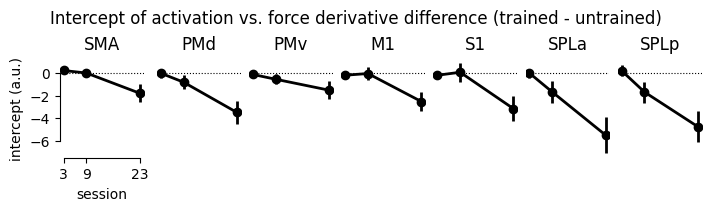

In [38]:
# intercept (± SEM) of the per-session fits, one panel per ROI
intercepts = util.regress_im_sess(diff_act, diff_force, rois, roi_col='regionname')
intercepts['sem_low']  = intercepts.coef - intercepts.se
intercepts['sem_high'] = intercepts.coef + intercepts.se
print(intercepts[['regionname', 'session', 'coef', 'ci_low', 'ci_high', 'tval', 'pval']])

fig, axs = plt.subplots(1, len(rois), constrained_layout=True, sharex=True, sharey=True, figsize=(7, 2))

vis.plot_ci_im_sess(fig, axs, intercepts, rois, x='session', y='coef', ci=('sem_low', 'sem_high'), color='k', add_zero=True)

sb.despine(ax=axs[0], trim=True)
axs[0].set_xlabel('session')
axs[0].set_ylabel('intercept (a.u.)')
fig.suptitle('Intercept of activation vs. force derivative difference (trained - untrained)')

plt.show()

## Activation vs. baseline (surface-based)

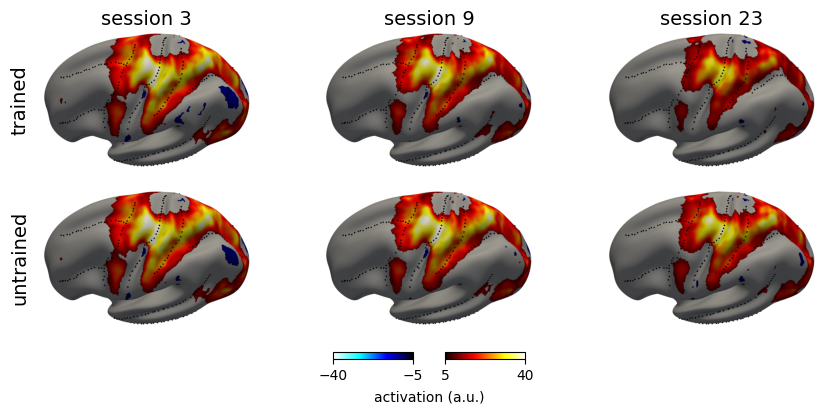

In [42]:
cold_colors = [(0, 0, 0), (0, 0, 1), (0, 1, 1), (1, 1, 1)]  # RGB tuples
cold = LinearSegmentedColormap.from_list('cold_custom', cold_colors, N=128)
hot = plt.cm.hot(np.linspace(0, 1, 128))
cold_vals = cold(np.linspace(1, 0, 128))  # reversed
combined = np.vstack((cold_vals, hot))
cmap = LinearSegmentedColormap.from_list('coldhot', combined)

dtype = 'con'
thresh = 5
vmin, vmax = -40, 40
H = 'L'

cifti = nb.load(os.path.join(gl.baseDir, gl.surfDir, f'glm{glm}.con.session.smooth.dscalar.nii'))
fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(8, 4.5), )
for gcol in range(6):
    row = 1 if gcol % 2 == 1 else 0
    col = gcol // 2
    ax = axs[row, col]
    fig, ax = plot_surf(fig, ax, cifti, H, cmap=cmap, col=gcol, thresh=thresh, vmin=vmin, vmax=vmax)

    if row==0:
        ax.set_title(f'session {gl.sessions[col]}', fontsize=14)
        if col==0:
            ax.text(0, .5, 'trained', transform=ax.transAxes, rotation=90, ha='right', va='center', fontsize=14)
    elif (row==1) & (col==0):
        ax.text(0, .5, 'untrained', transform=ax.transAxes, rotation=90, ha='right', va='center', fontsize=14)

    cold_half = LinearSegmentedColormap.from_list("cold_half", combined[:128])
    hot_half = LinearSegmentedColormap.from_list("hot_half", combined[128:])

neg_norm = Normalize(vmin=vmin, vmax=-thresh)
sm_neg = ScalarMappable(norm=neg_norm, cmap=cold_half)
cax_neg = fig.add_axes([0.38, 0.15, 0.1, 0.015])
cbar_neg = fig.colorbar(sm_neg, ax=ax, cax=cax_neg, pad=0.01, orientation='horizontal')
cbar_neg.set_ticks([vmin, -thresh])
fig.supxlabel('activation (a.u.)', fontsize=10, y=.05)

pos_norm = Normalize(vmin=thresh, vmax=vmax)
sm_pos = ScalarMappable(norm=pos_norm, cmap=hot_half)
cax_pos = fig.add_axes([0.52, 0.15, 0.1, 0.015])
cbar_pos = fig.colorbar(sm_pos, ax=ax, cax=cax_pos, pad=0.01, orientation='horizontal')
cbar_pos.set_ticks([thresh, vmax])

# fig.suptitle('Surface activation (left hemisphere)')

plt.subplots_adjust(left=0, right=1, bottom=.2, top=.9, hspace=0)

fig.savefig(os.path.join(gl.figDir, f'surf_activation.{H}.pdf'), dpi=600)

plt.show()

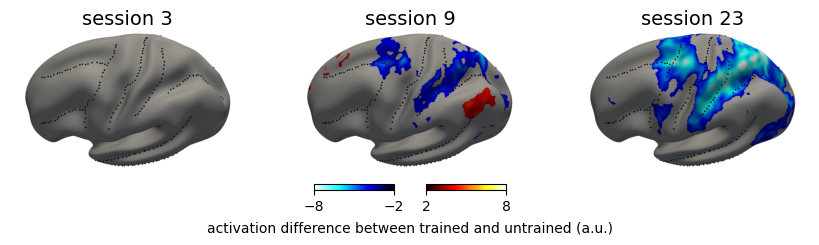

In [43]:
vmin, vmax = -8, 8
thresh = 2
cifti = nb.load(os.path.join(gl.baseDir, gl.surfDir, f'glm{glm}.con.trained_vs_untrained.smooth.dscalar.nii'))
fig, axs = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(8, 3), )
for col in range(3):
    ax = axs[col]
    fig, ax = plot_surf(fig, ax, cifti, H, cmap=cmap, col=col, thresh=thresh, vmin=vmin, vmax=vmax)

    ax.set_title(f'session {gl.sessions[col]}', fontsize=14)

    cold_half = LinearSegmentedColormap.from_list("cold_half", combined[:128])
    hot_half = LinearSegmentedColormap.from_list("hot_half", combined[128:])

neg_norm = Normalize(vmin=vmin, vmax=-thresh)
sm_neg = ScalarMappable(norm=neg_norm, cmap=cold_half)
cax_neg = fig.add_axes([0.38, 0.2, 0.1, 0.02])
cbar_neg = fig.colorbar(sm_neg, ax=ax, cax=cax_neg, pad=0.01, orientation='horizontal')
cbar_neg.set_ticks([vmin, -thresh])
fig.supxlabel('activation difference between trained and untrained (a.u.)', fontsize=10, y=.05)

pos_norm = Normalize(vmin=thresh, vmax=vmax)
sm_pos = ScalarMappable(norm=pos_norm, cmap=hot_half)
cax_pos = fig.add_axes([0.52, 0.2, 0.1, 0.02])
cbar_pos = fig.colorbar(sm_pos, ax=ax, cax=cax_pos, pad=0.01, orientation='horizontal')
cbar_pos.set_ticks([thresh, vmax])

#fig.suptitle('Trained vs. untrained activation (left hemisphere)')

plt.subplots_adjust(left=0, right=1, bottom=.1, top=.9, hspace=0)

fig.savefig(os.path.join(gl.figDir, f'surf_activation_diff.{H}.pdf'), dpi=600)

plt.show()